# Introduction

Since Jan. 1, 2015, [The Washington Post](https://www.washingtonpost.com/) has been compiling a database of every fatal shooting in the US by a police officer in the line of duty. 

<center><img src=https://i.imgur.com/sX3K62b.png></center>

While there are many challenges regarding data collection and reporting, The Washington Post has been tracking more than a dozen details about each killing. This includes the race, age and gender of the deceased, whether the person was armed, and whether the victim was experiencing a mental-health crisis. The Washington Post has gathered this supplemental information from law enforcement websites, local new reports, social media, and by monitoring independent databases such as "Killed by police" and "Fatal Encounters". The Post has also conducted additional reporting in many cases.

There are 4 additional datasets: US census data on poverty rate, high school graduation rate, median household income, and racial demographics. [Source of census data](https://factfinder.census.gov/faces/nav/jsf/pages/community_facts.xhtml).

### Upgrade Plotly

Run the cell below if you are working with Google Colab

In [1]:
%pip install --upgrade plotly

Note: you may need to restart the kernel to use updated packages.


## Import Statements

In [2]:
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

## Notebook Presentation

In [7]:
pd.options.display.float_format = '{:,.2f}'.format

## Load the Data

In [8]:
df_hh_income = pd.read_csv('Median_Household_Income_2015.csv', encoding="windows-1252")
df_pct_poverty = pd.read_csv('Pct_People_Below_Poverty_Level.csv', encoding="windows-1252")
df_pct_completed_hs = pd.read_csv('Pct_Over_25_Completed_High_School.csv', encoding="windows-1252")
df_share_race_city = pd.read_csv('Share_of_Race_By_City.csv', encoding="windows-1252")
df_fatalities = pd.read_csv('Deaths_by_Police_US.csv', encoding="windows-1252")

# Preliminary Data Exploration

* What is the shape of the DataFrames? 
* How many rows and columns do they have?
* What are the column names?
* Are there any NaN values or duplicates?

In [18]:
print("Household Income:", df_hh_income.shape)
print("Poverty:", df_pct_poverty.shape)
print("High School Completion:", df_pct_completed_hs.shape)
print("Race by City:", df_share_race_city.shape)
print("Police Fatalities:", df_fatalities.shape)

Household Income: (29322, 3)
Poverty: (29329, 3)
High School Completion: (29329, 3)
Race by City: (29268, 7)
Police Fatalities: (2535, 14)


In [19]:
print("Household Income: Rows =", df_hh_income.shape[0], "| Columns =", df_hh_income.shape[1])
print("Poverty: Rows =", df_pct_poverty.shape[0], "| Columns =", df_pct_poverty.shape[1])
print("High School Completion: Rows =", df_pct_completed_hs.shape[0], "| Columns =", df_pct_completed_hs.shape[1])
print("Race by City: Rows =", df_share_race_city.shape[0], "| Columns =", df_share_race_city.shape[1])
print("Police Fatalities: Rows =", df_fatalities.shape[0], "| Columns =", df_fatalities.shape[1])

Household Income: Rows = 29322 | Columns = 3
Poverty: Rows = 29329 | Columns = 3
High School Completion: Rows = 29329 | Columns = 3
Race by City: Rows = 29268 | Columns = 7
Police Fatalities: Rows = 2535 | Columns = 14


In [46]:
dataframes = {
    "Household Income": df_hh_income,
    "Poverty": df_pct_poverty,
    "High School Completion": df_pct_completed_hs,
    "Race by City": df_share_race_city,
    "Police Fatalities": df_fatalities
}

for name, df in dataframes.items():
    print(f"\n{name}")
    print(df.columns.tolist())


Household Income
['Geographic Area', 'City', 'Median Income']

Poverty
['Geographic Area', 'City', 'poverty_rate']

High School Completion
['Geographic Area', 'City', 'percent_completed_hs']

Race by City
['Geographic area', 'City', 'share_white', 'share_black', 'share_native_american', 'share_asian', 'share_hispanic']

Police Fatalities
['id', 'name', 'date', 'manner_of_death', 'armed', 'age', 'gender', 'race', 'city', 'state', 'signs_of_mental_illness', 'threat_level', 'flee', 'body_camera']


In [47]:
dataframes = {
    "Household Income": df_hh_income,
    "Poverty": df_pct_poverty,
    "High School Completion": df_pct_completed_hs,
    "Race by City": df_share_race_city,
    "Police Fatalities": df_fatalities
}

for name, df in dataframes.items():
    print(f"\n{name}")
    print("NaN values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())


Household Income
NaN values: 0
Duplicate rows: 0

Poverty
NaN values: 201
Duplicate rows: 0

High School Completion
NaN values: 197
Duplicate rows: 0

Race by City
NaN values: 100
Duplicate rows: 0

Police Fatalities
NaN values: 0
Duplicate rows: 0


## Data Cleaning - Check for Missing Values and Duplicates

Consider how to deal with the NaN values. Perhaps substituting 0 is appropriate. 

In [27]:
dataframes = {
    "Household Income": df_hh_income,
    "Poverty": df_pct_poverty,
    "High School Completion": df_pct_completed_hs,
    "Race by City": df_share_race_city,
    "Police Fatalities": df_fatalities
}

for name, df in dataframes.items():
    for column in df.columns:
        if df[column].dtype == "string" or df[column].dtype == "object":
            df[column] = df[column].fillna("Unknown")
        else:
            df[column] = df[column].fillna(0)

for name, df in dataframes.items():
    print(f"\n{name}")
    print("Remaining NaN values:", df.isnull().sum().sum())


Household Income
Remaining NaN values: 0

Poverty
Remaining NaN values: 0

High School Completion
Remaining NaN values: 0

Race by City
Remaining NaN values: 0

Police Fatalities
Remaining NaN values: 0


In [30]:
for name, df in dataframes.items():
    dataframes[name] = df.drop_duplicates()
    print(f"{name}: {dataframes[name].duplicated().sum()} duplicate rows remaining")

Household Income: 0 duplicate rows remaining
Poverty: 0 duplicate rows remaining
High School Completion: 0 duplicate rows remaining
Race by City: 0 duplicate rows remaining
Police Fatalities: 0 duplicate rows remaining


In [29]:
df_hh_income = dataframes["Household Income"]
df_pct_poverty = dataframes["Poverty"]
df_pct_completed_hs = dataframes["High School Completion"]
df_share_race_city = dataframes["Race by City"]
df_fatalities = dataframes["Police Fatalities"]

# Chart the Poverty Rate in each US State

Create a bar chart that ranks the poverty rate from highest to lowest by US state. Which state has the highest poverty rate? Which state has the lowest poverty rate?  Bar Plot

In [34]:
# Convert poverty_rate into numeric values
df_pct_poverty["poverty_rate"] = pd.to_numeric(
    df_pct_poverty["poverty_rate"],
    errors="coerce"
)

In [35]:
# Calculate average poverty rate for each state
poverty_by_state = df_pct_poverty.groupby(
    "Geographic Area"
)["poverty_rate"].mean().reset_index()

# Sort from highest to lowest
poverty_by_state = poverty_by_state.sort_values(
    by="poverty_rate",
    ascending=False
)

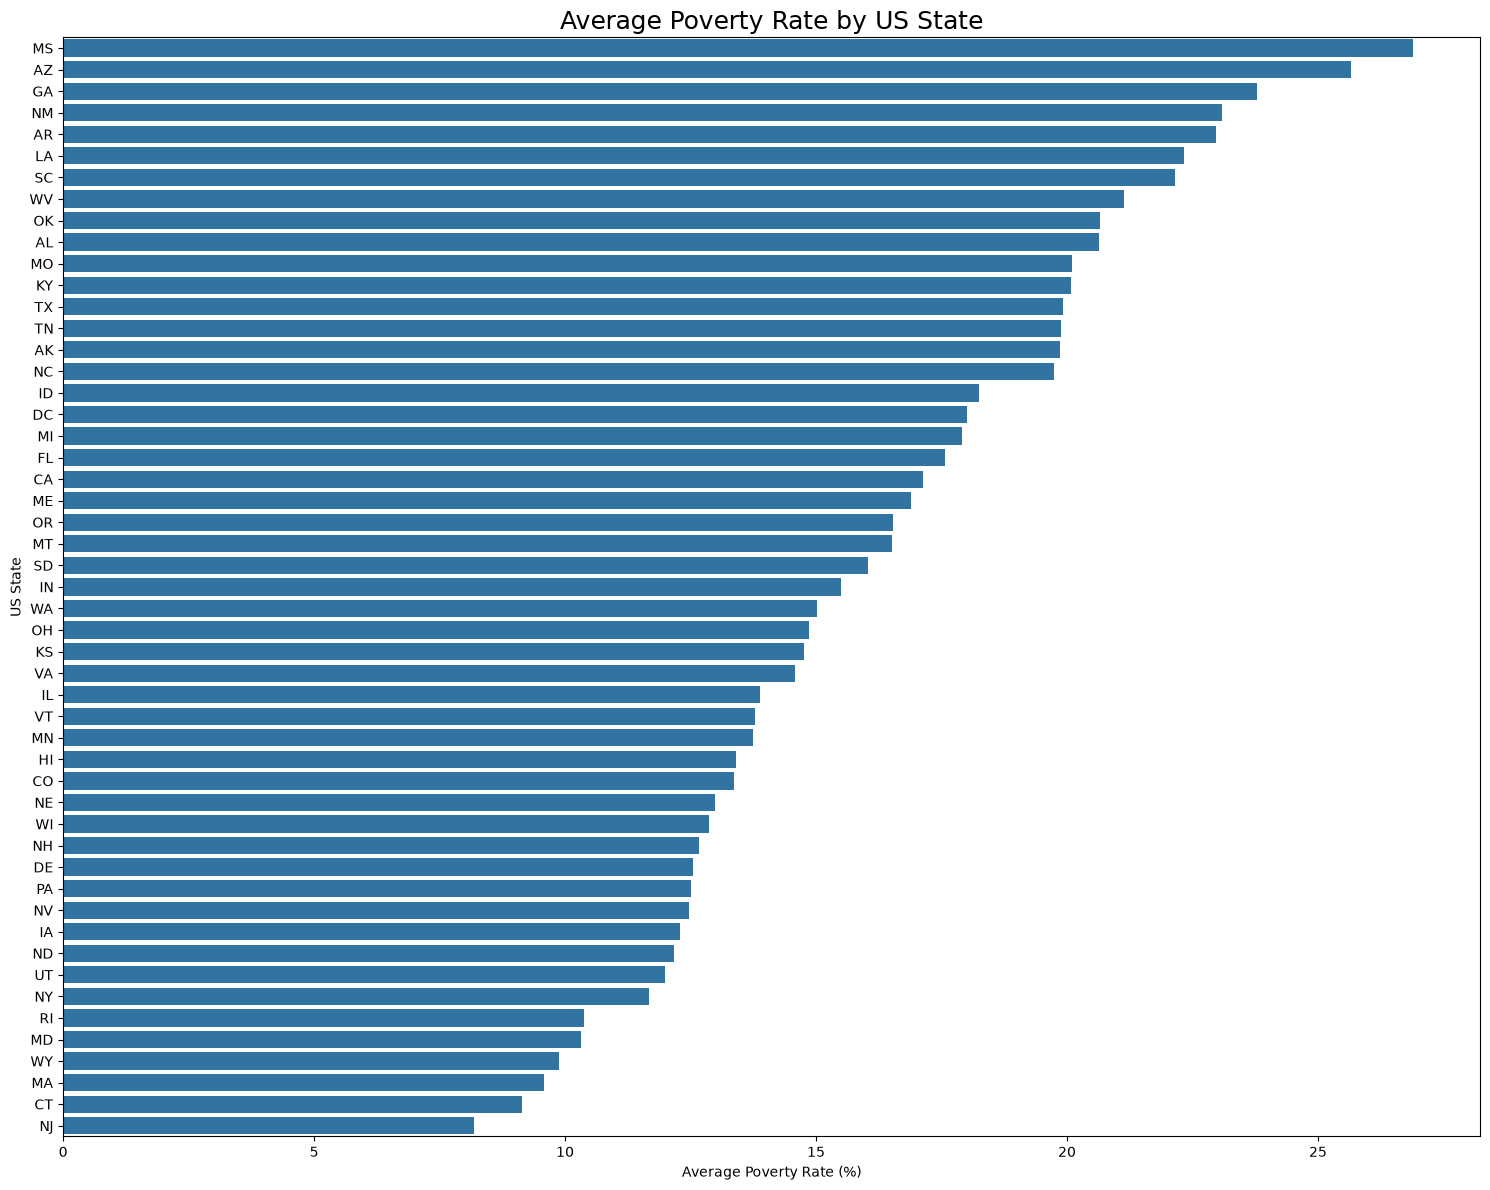

Highest poverty rate:
Geographic Area      MS
poverty_rate      26.88
Name: 25, dtype: object

Lowest poverty rate:
Geographic Area     NJ
poverty_rate      8.19
Name: 31, dtype: object


In [36]:
plt.figure(figsize=(15, 12))

sns.barplot(
    data=poverty_by_state,
    x="poverty_rate",
    y="Geographic Area"
)

plt.title("Average Poverty Rate by US State", fontsize=18)
plt.xlabel("Average Poverty Rate (%)")
plt.ylabel("US State")
plt.tight_layout()
plt.show()

# Highest and lowest poverty rates
print("Highest poverty rate:")
print(poverty_by_state.iloc[0])

print("\nLowest poverty rate:")
print(poverty_by_state.iloc[-1])

# Chart the High School Graduation Rate by US State

Show the High School Graduation Rate in ascending order of US States. Which state has the lowest high school graduation rate? Which state has the highest?

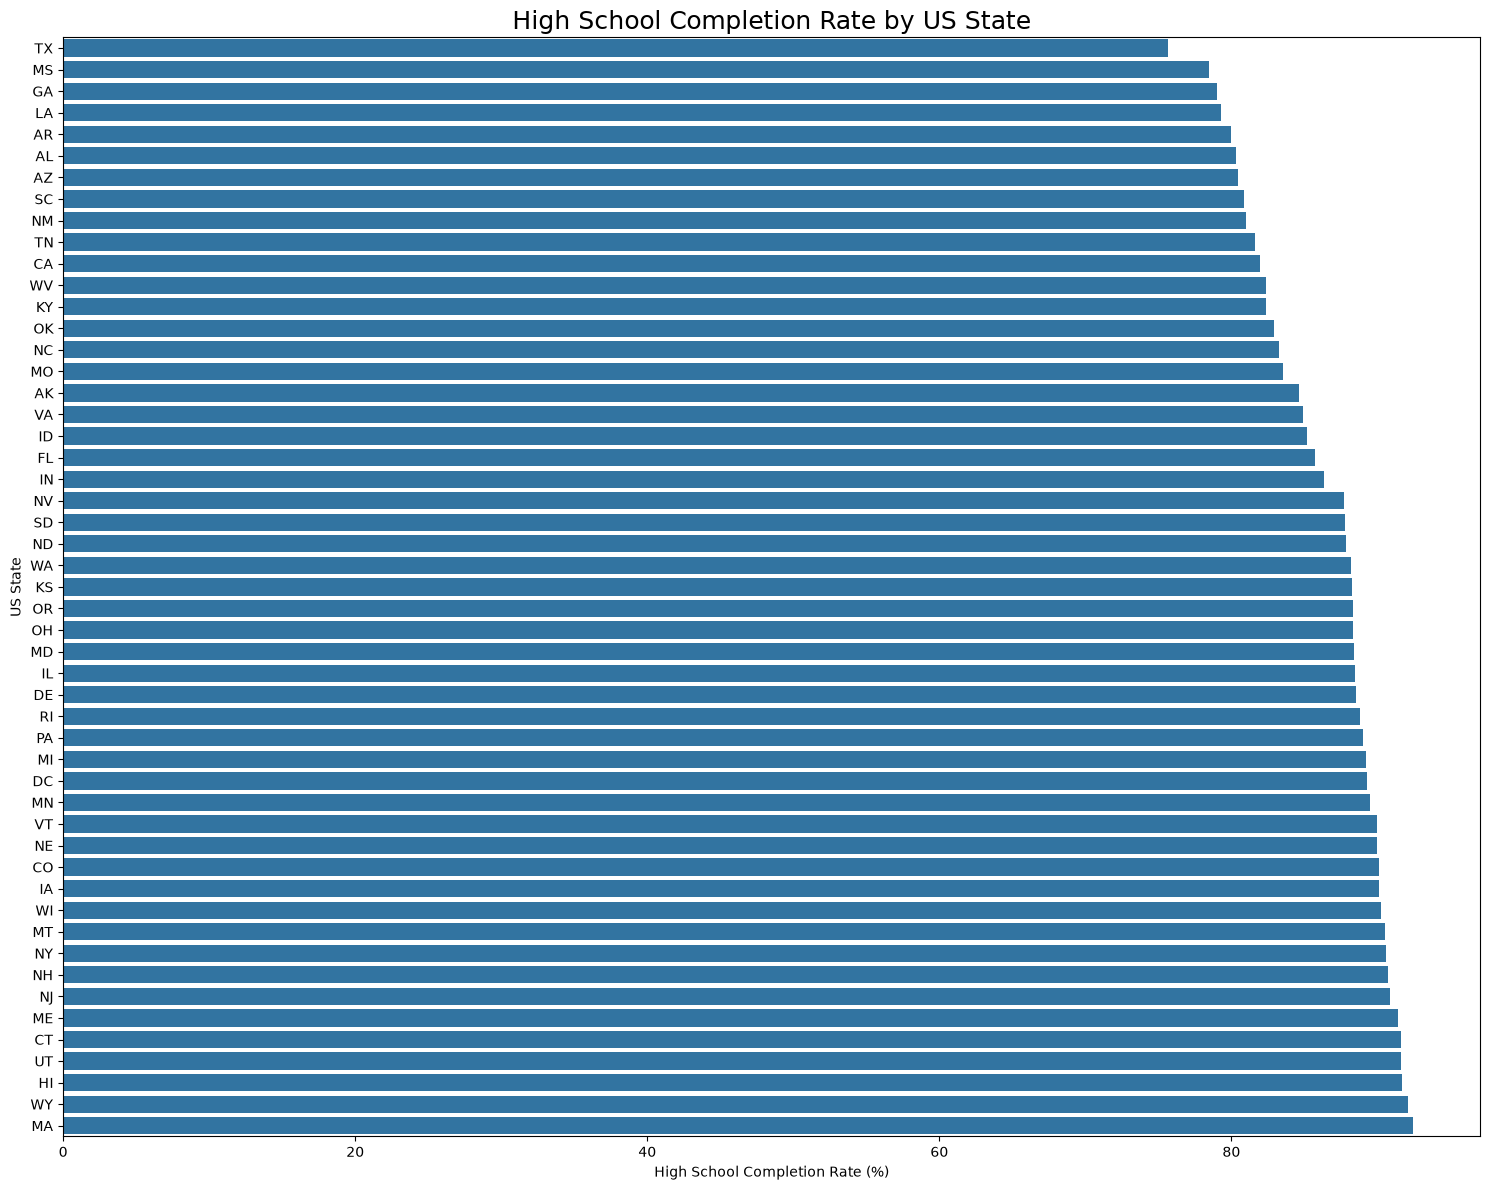

Lowest completion rate:
Geographic Area           TX
percent_completed_hs   75.69
Name: 43, dtype: object

Highest completion rate:
Geographic Area           MA
percent_completed_hs   92.40
Name: 19, dtype: object


In [37]:
# Convert column to numeric
df_pct_completed_hs["percent_completed_hs"] = pd.to_numeric(
    df_pct_completed_hs["percent_completed_hs"],
    errors="coerce"
)

# Group by state and calculate average
hs_by_state = df_pct_completed_hs.groupby(
    "Geographic Area"
)["percent_completed_hs"].mean().reset_index()

# Sort from lowest to highest
hs_by_state = hs_by_state.sort_values(
    by="percent_completed_hs",
    ascending=True
)

# plot
plt.figure(figsize=(15, 12))

sns.barplot(
    data=hs_by_state,
    x="percent_completed_hs",
    y="Geographic Area"
)

plt.title("High School Completion Rate by US State", fontsize=18)
plt.xlabel("High School Completion Rate (%)")
plt.ylabel("US State")
plt.tight_layout()
plt.show()

# Find lowest and highest
print("Lowest completion rate:")
print(hs_by_state.iloc[0])

print("\nHighest completion rate:")
print(hs_by_state.iloc[-1])

# Visualise the Relationship between Poverty Rates and High School Graduation Rates

#### Create a line chart with two y-axes to show if the rations of poverty and high school graduation move together.  

In [39]:
# Merge both datasets by state
combined = pd.merge(
    poverty_by_state,
    hs_by_state,
    on="Geographic Area"
)

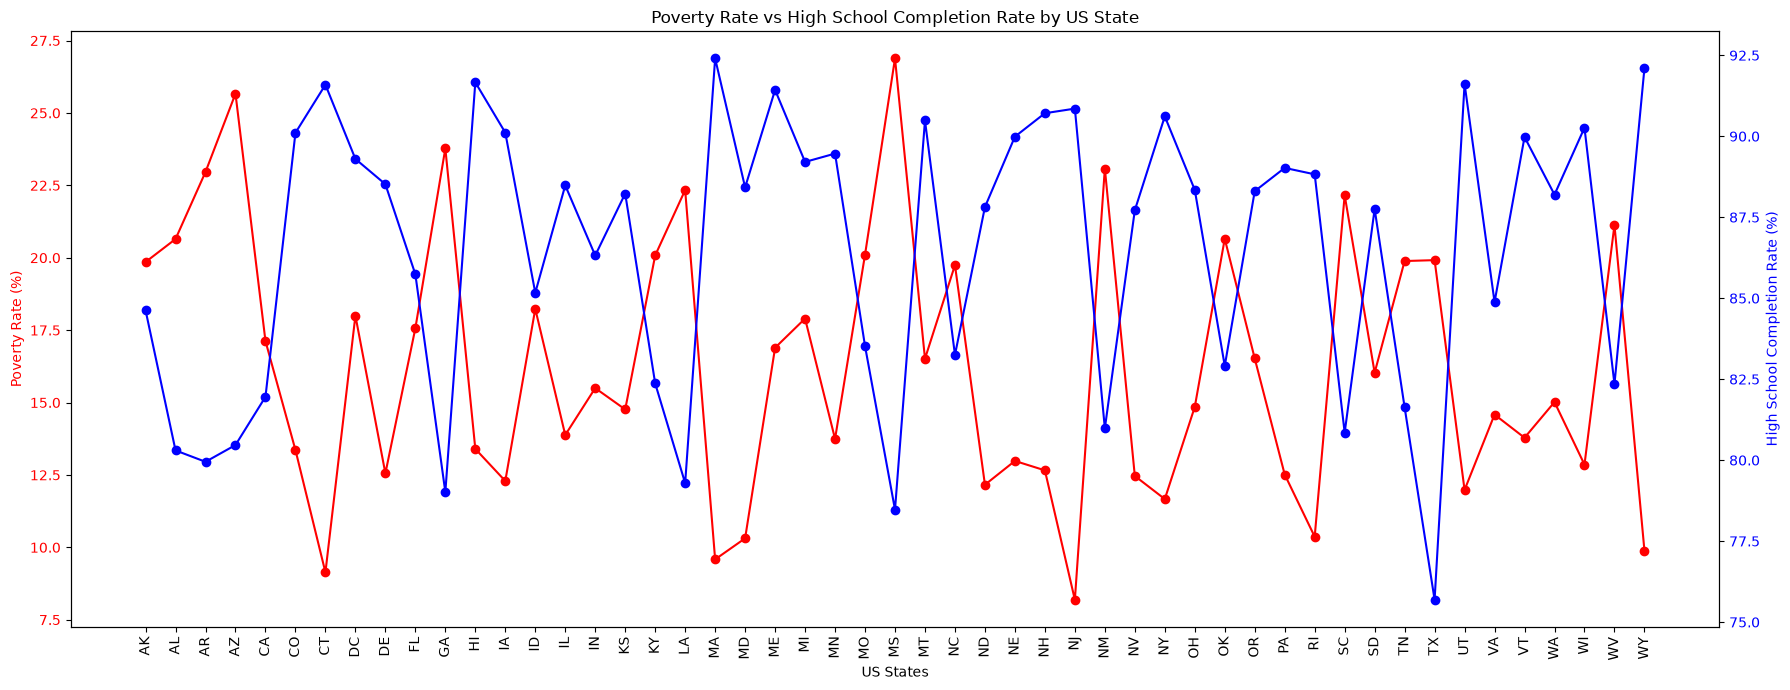

In [40]:
# Sort states alphabetically
combined = combined.sort_values("Geographic Area")

# Create chart
fig, ax1 = plt.subplots(figsize=(18, 7))

# First Y-axis: Poverty rate
ax1.plot(
    combined["Geographic Area"],
    combined["poverty_rate"],
    color="red",
    marker="o",
    label="Poverty Rate"
)

ax1.set_xlabel("US States")
ax1.set_ylabel("Poverty Rate (%)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Second Y-axis: High school completion rate
ax2 = ax1.twinx()

ax2.plot(
    combined["Geographic Area"],
    combined["percent_completed_hs"],
    color="blue",
    marker="o",
    label="High School Completion Rate"
)

ax2.set_ylabel("High School Completion Rate (%)", color="blue")
ax2.tick_params(axis="y", labelcolor="blue")

plt.title("Poverty Rate vs High School Completion Rate by US State")

ax1.tick_params(axis="x", rotation=90)

fig.tight_layout()
plt.show()

#### Now use a Seaborn .jointplot() with a Kernel Density Estimate (KDE) and/or scatter plot to visualise the same relationship

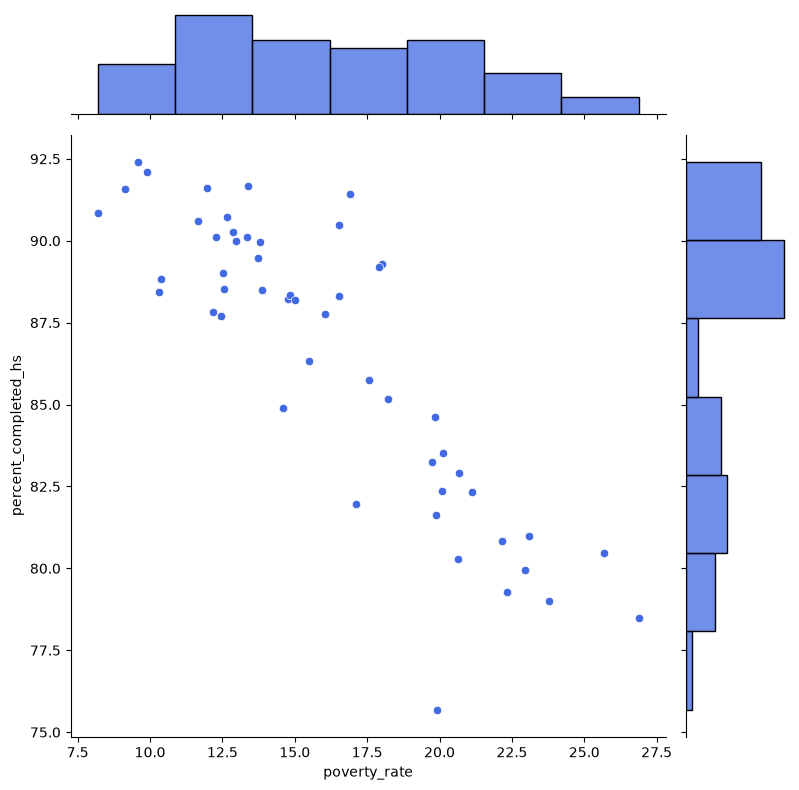

In [41]:
sns.jointplot(
    data=combined,
    x="poverty_rate",
    y="percent_completed_hs",
    kind="scatter",
    height=8,
    color="royalblue"
)

plt.show()

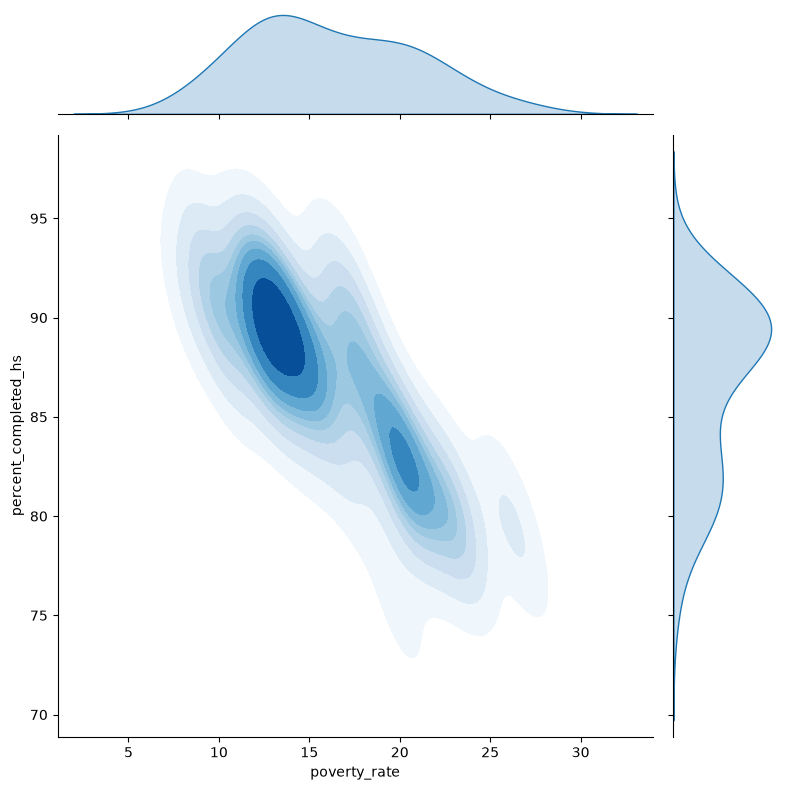

In [42]:
sns.jointplot(
    data=combined,
    x="poverty_rate",
    y="percent_completed_hs",
    kind="kde",
    fill=True,
    height=8,
    cmap="Blues"
)

plt.show()

#### Seaborn's `.lmplot()` or `.regplot()` to show a linear regression between the poverty ratio and the high school graduation ratio. 

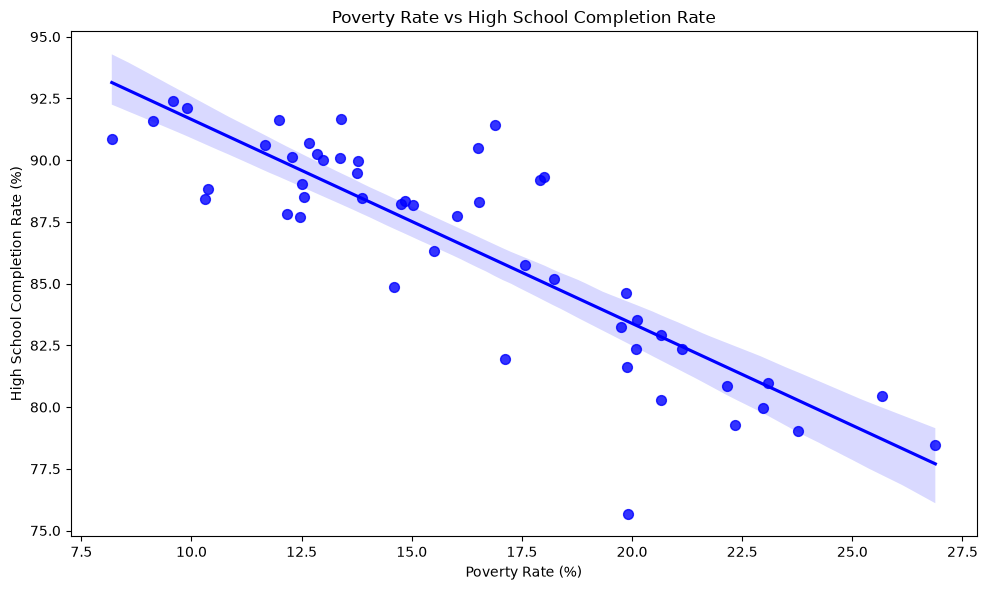

In [43]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=combined,
    x="poverty_rate",
    y="percent_completed_hs",
    color="blue",
    scatter_kws={"s": 50}
)

plt.title("Poverty Rate vs High School Completion Rate")
plt.xlabel("Poverty Rate (%)")
plt.ylabel("High School Completion Rate (%)")

plt.tight_layout()
plt.show()

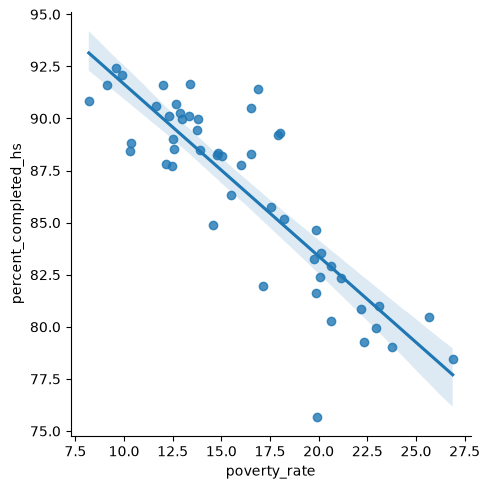

In [44]:
sns.lmplot(
    data=combined,
    x="poverty_rate",
    y="percent_completed_hs"
)

plt.show()

# Create a Bar Chart with Subsections Showing the Racial Makeup of Each US State

Visualise the share of the white, black, hispanic, asian and native american population in each US State using a bar chart with sub sections. 

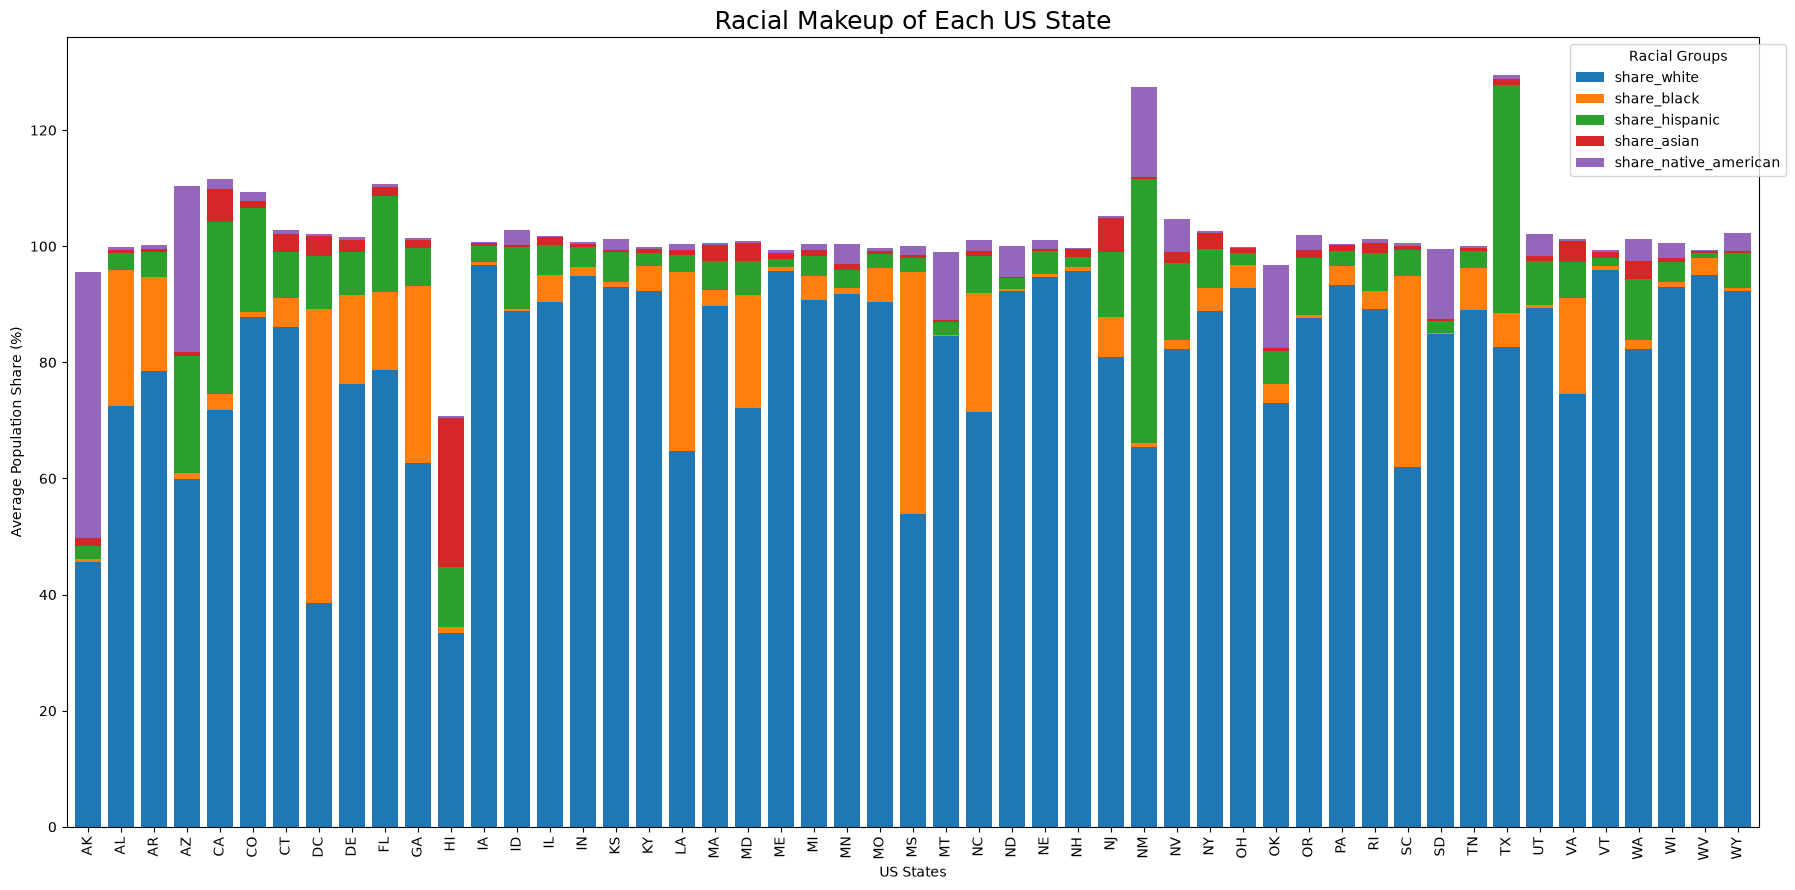

In [48]:
race_columns = [
    "share_white",
    "share_black",
    "share_hispanic",
    "share_asian",
    "share_native_american"
]

# Convert percentages to numeric
for col in race_columns:
    df_share_race_city[col] = pd.to_numeric(
        df_share_race_city[col].astype(str).str.replace("%", ""),
        errors="coerce"
    )

# Group by state and calculate average
race_by_state = df_share_race_city.groupby(
    "Geographic area"
)[race_columns].mean().reset_index()

# Sort alphabetically
race_by_state = race_by_state.sort_values("Geographic area")

# Create stacked bar chart
race_by_state.set_index("Geographic area")[race_columns].plot(
    kind="bar",
    stacked=True,
    figsize=(18, 9),
    width=0.8
)

plt.title("Racial Makeup of Each US State", fontsize=18)
plt.xlabel("US States")
plt.ylabel("Average Population Share (%)")
plt.xticks(rotation=90)
plt.legend(title="Racial Groups", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# Create Donut Chart by of People Killed by Race

Hint: Use `.value_counts()`

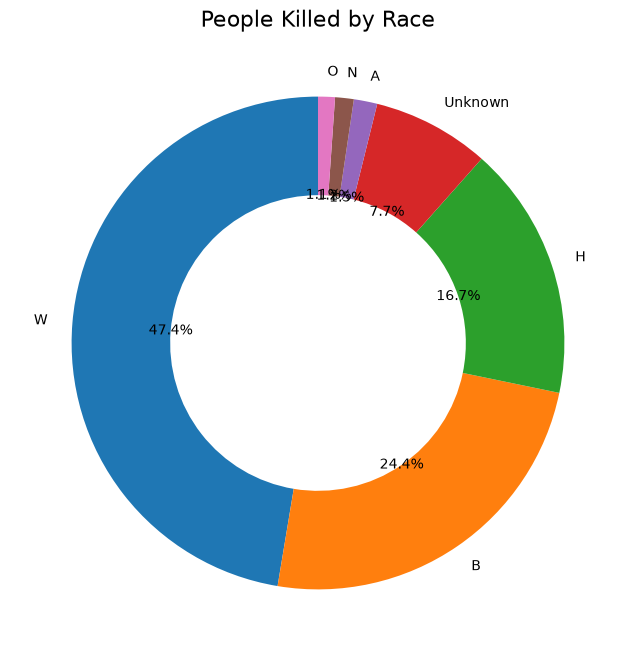

In [49]:
race_counts = df_fatalities["race"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    race_counts,
    labels=race_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("People Killed by Race", fontsize=16)
plt.show()

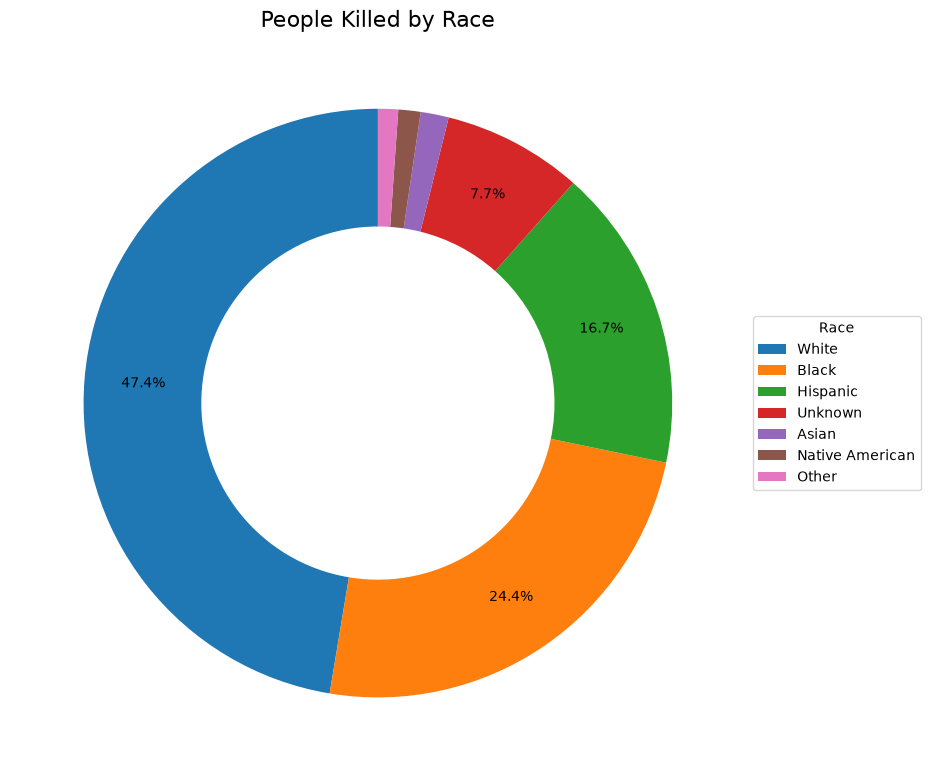

In [51]:
race_counts = df_fatalities["race"].value_counts()

race_labels = {
    "W": "White",
    "B": "Black",
    "H": "Hispanic",
    "A": "Asian",
    "N": "Native American",
    "O": "Other",
    "Unknown": "Unknown"
}

race_counts.index = race_counts.index.map(
    lambda x: race_labels.get(x, x)
)

plt.figure(figsize=(9, 8))

plt.pie(
    race_counts,
    labels=None,
    autopct=lambda p: f"{p:.1f}%" if p >= 3 else "",
    startangle=90,
    pctdistance=0.8,
    wedgeprops={"width": 0.4}
)

plt.legend(
    race_counts.index,
    title="Race",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("People Killed by Race", fontsize=16)
plt.tight_layout()
plt.show()

# Create a Chart Comparing the Total Number of Deaths of Men and Women

Use `df_fatalities` to illustrate how many more men are killed compared to women. 

gender
M    2428
F     107
Name: count, dtype: int64


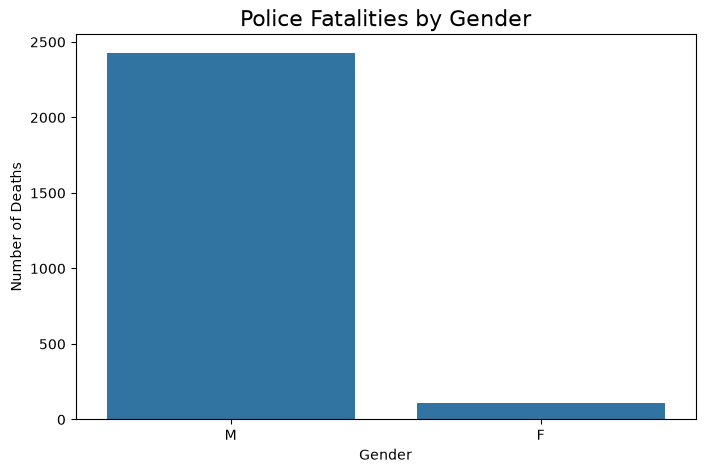

Men killed: 2428
Women killed: 107
Difference: 2321


In [52]:
gender_counts = df_fatalities["gender"].value_counts()

print(gender_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values
)

plt.title("Police Fatalities by Gender", fontsize=16)
plt.xlabel("Gender")
plt.ylabel("Number of Deaths")

plt.show()

print("Men killed:", gender_counts.get("M", 0))
print("Women killed:", gender_counts.get("F", 0))
print("Difference:", gender_counts.get("M", 0) - gender_counts.get("F", 0))

# Create a Box Plot Showing the Age and Manner of Death

Break out the data by gender using `df_fatalities`. Is there a difference between men and women in the manner of death? 

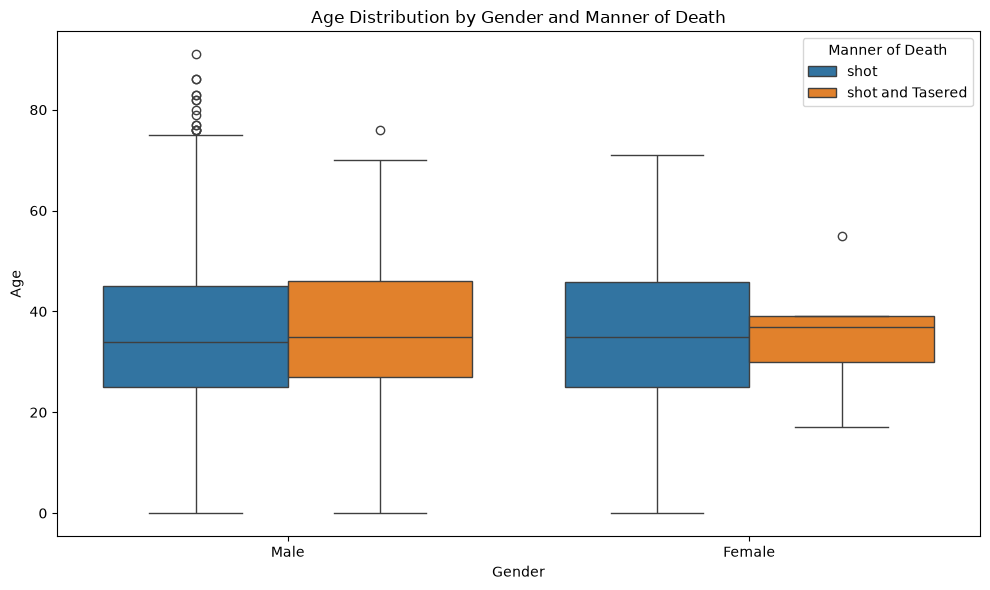

In [53]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_fatalities,
    x="gender",
    y="age",
    hue="manner_of_death"
)

plt.title("Age Distribution by Gender and Manner of Death")
plt.xlabel("Gender")
plt.ylabel("Age")
plt.xticks([0, 1], ["Male", "Female"])
plt.legend(title="Manner of Death")
plt.tight_layout()
plt.show()

# Were People Armed? 

In what percentage of police killings were people armed? Create chart that show what kind of weapon (if any) the deceased was carrying. How many of the people killed by police were armed with guns versus unarmed? 

In [54]:
df_fatalities["armed"].value_counts()

armed
gun                        1398
knife                       373
vehicle                     177
unarmed                     171
undetermined                117
                           ... 
air conditioner               1
pole and knife                1
baseball bat and bottle       1
fireworks                     1
pen                           1
Name: count, Length: 69, dtype: int64

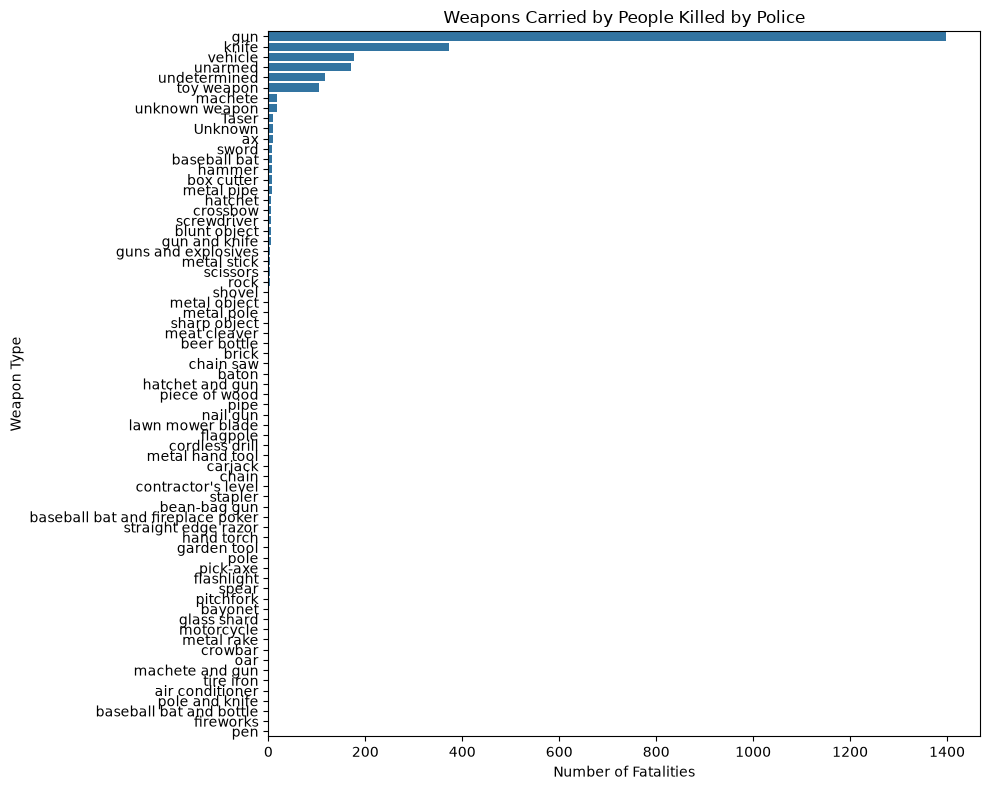

In [61]:
weapon_counts = df_fatalities["armed"].value_counts()

plt.figure(figsize=(10, 8))

sns.barplot(
    x=weapon_counts.values,
    y=weapon_counts.index
)

plt.title("Weapons Carried by People Killed by Police")
plt.xlabel("Number of Fatalities")
plt.ylabel("Weapon Type")
plt.tight_layout()
plt.show()

In [63]:
armed_counts = df_fatalities["armed"].value_counts()

total = len(df_fatalities)

unarmed = armed_counts.get("unarmed", 0)
guns = armed_counts.get("gun", 0)

unknown = armed_counts.get("undetermined", 0) + armed_counts.get("unknown", 0)

# All categories other than unarmed and unknown
armed = total - unarmed - unknown

print("Total fatalities:", total)
print("Armed (excluding unknown):", armed)
print("Unarmed:", unarmed)
print("Armed with guns:", guns)
print("Unknown / undetermined:", unknown)

print("Percentage armed:", round(armed / total * 100, 2), "%")
print("Percentage unarmed:", round(unarmed / total * 100, 2), "%")
print("Percentage armed with guns:", round(guns / total * 100, 2), "%")

Total fatalities: 2535
Armed (excluding unknown): 2247
Unarmed: 171
Armed with guns: 1398
Unknown / undetermined: 117
Percentage armed: 88.64 %
Percentage unarmed: 6.75 %
Percentage armed with guns: 55.15 %


# How Old Were the People Killed?

Work out what percentage of people killed were under 25 years old.  

In [64]:
under_25 = df_fatalities[df_fatalities["age"] < 25]

under_25_count = len(under_25)
total = df_fatalities["age"].count()

percentage = (under_25_count / total) * 100

print("People under 25:", under_25_count)
print("Total people with recorded age:", total)
print("Percentage under 25:", round(percentage, 2), "%")

People under 25: 527
Total people with recorded age: 2535
Percentage under 25: 20.79 %


Create a histogram and KDE plot that shows the distribution of ages of the people killed by police. 

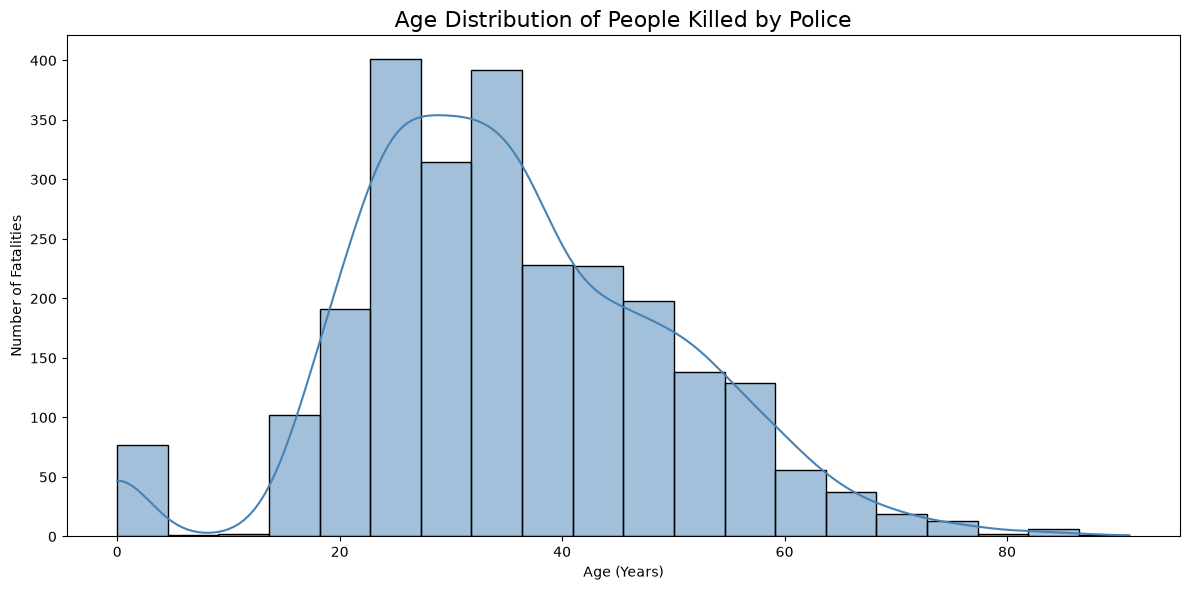

In [65]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_fatalities,
    x="age",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Age Distribution of People Killed by Police", fontsize=16)
plt.xlabel("Age (Years)")
plt.ylabel("Number of Fatalities")

plt.tight_layout()
plt.show()

Create a seperate KDE plot for each race. Is there a difference between the distributions? 

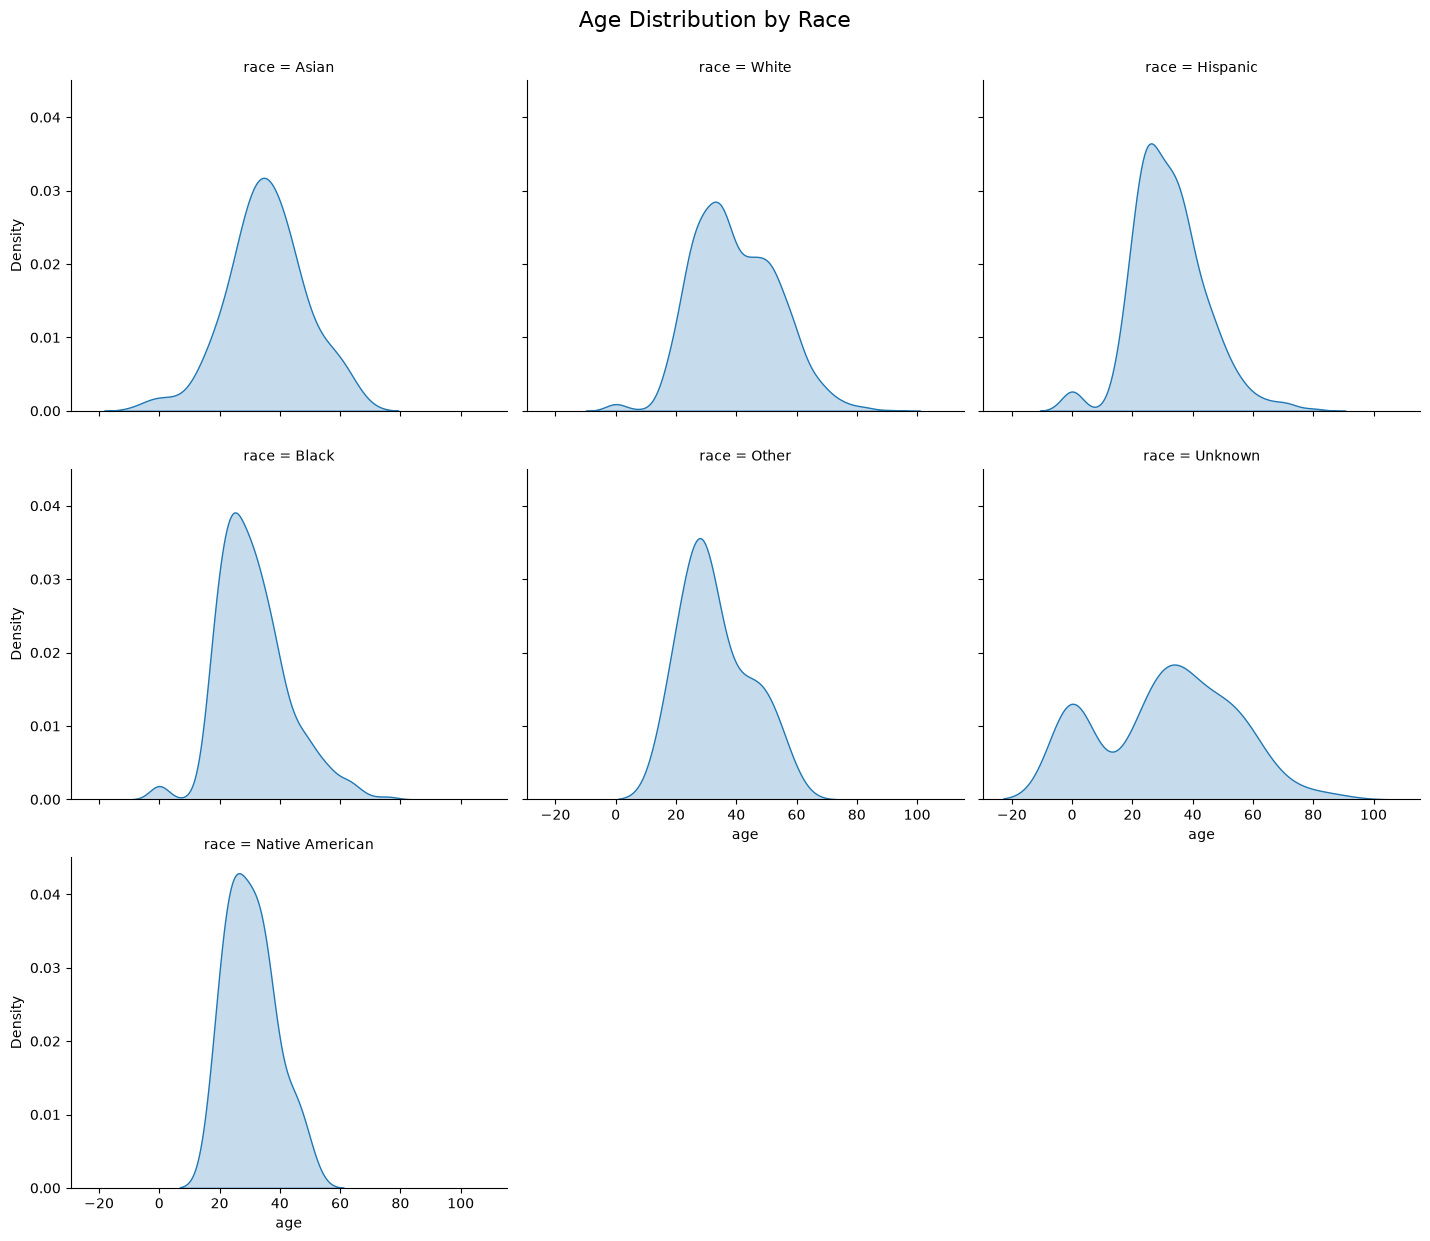

In [66]:
race_labels = {
    "W": "White",
    "B": "Black",
    "H": "Hispanic",
    "A": "Asian",
    "N": "Native American",
    "O": "Other"
}

plot_df = df_fatalities.dropna(subset=["age", "race"]).copy()

plot_df["race"] = plot_df["race"].map(
    lambda x: race_labels.get(x, x)
)

sns.displot(
    data=plot_df,
    x="age",
    col="race",
    col_wrap=3,
    kind="kde",
    fill=True,
    common_norm=False,
    height=4,
    aspect=1.2
)

plt.suptitle("Age Distribution by Race", y=1.03, fontsize=16)
plt.show()

# Race of People Killed

Create a chart that shows the total number of people killed by race. 

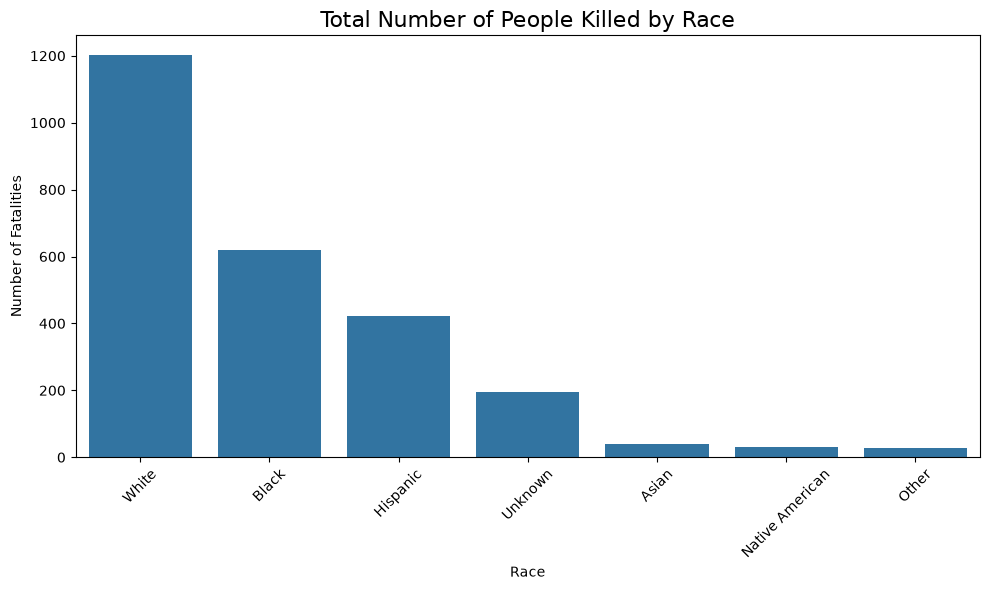

In [67]:
race_counts = df_fatalities["race"].value_counts()

race_labels = {
    "W": "White",
    "B": "Black",
    "H": "Hispanic",
    "A": "Asian",
    "N": "Native American",
    "O": "Other",
    "Unknown": "Unknown"
}

race_counts.index = race_counts.index.map(
    lambda x: race_labels.get(x, x)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=race_counts.index,
    y=race_counts.values
)

plt.title("Total Number of People Killed by Race", fontsize=16)
plt.xlabel("Race")
plt.ylabel("Number of Fatalities")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Mental Illness and Police Killings

What percentage of people killed by police have been diagnosed with a mental illness?

In [68]:
mental_illness_counts = df_fatalities["signs_of_mental_illness"].value_counts()

diagnosed = mental_illness_counts.get(True, 0)
total = len(df_fatalities)

percentage = (diagnosed / total) * 100

print("People with signs of mental illness:", diagnosed)
print("Total fatalities:", total)
print("Percentage:", round(percentage, 2), "%")

People with signs of mental illness: 633
Total fatalities: 2535
Percentage: 24.97 %


# In Which Cities Do the Most Police Killings Take Place?

Create a chart ranking the top 10 cities with the most police killings. Which cities are the most dangerous?  

In [69]:
city_counts = df_fatalities["city"].value_counts()
top_10_cities = city_counts.head(10)
print(top_10_cities)

city
Los Angeles    39
Phoenix        31
Houston        27
Chicago        25
Las Vegas      21
San Antonio    20
Columbus       19
Austin         18
Miami          18
St. Louis      15
Name: count, dtype: int64


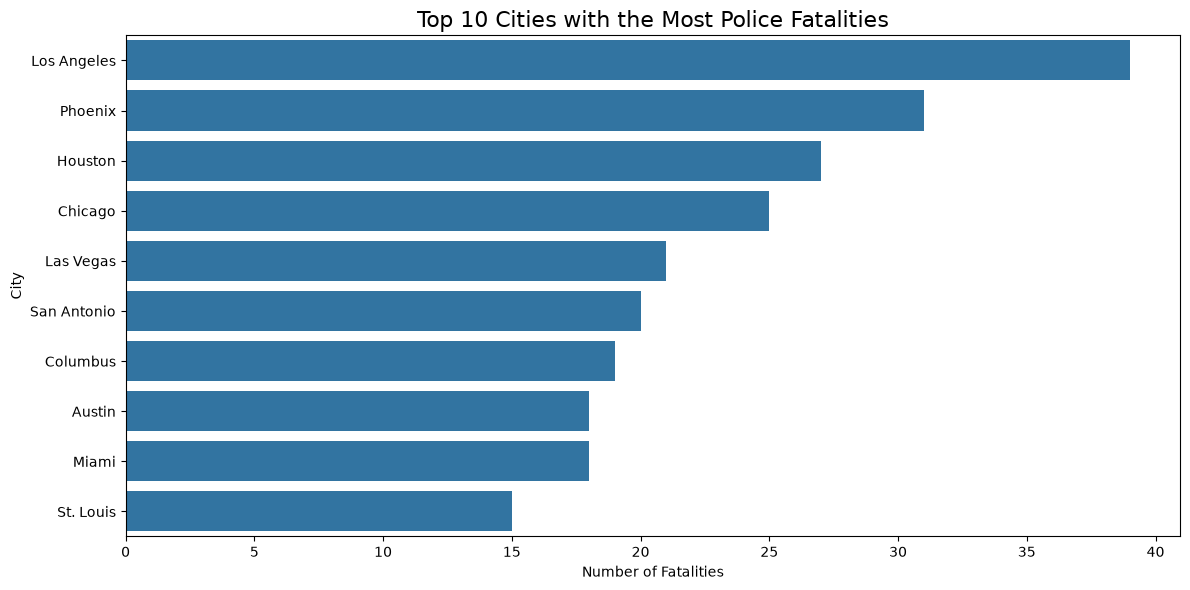

In [70]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_cities.values,
    y=top_10_cities.index
)

plt.title("Top 10 Cities with the Most Police Fatalities", fontsize=16)
plt.xlabel("Number of Fatalities")
plt.ylabel("City")

plt.tight_layout()
plt.show()

# Rate of Death by Race

Find the share of each race in the top 10 cities. Contrast this with the top 10 cities of police killings to work out the rate at which people are killed by race for each city. 

In [74]:
# 1. Get top 10 cities
top10_names = city_counts.head(10).index.tolist()

# 2. Standardise city names in both datasets
def clean_city(series):
    return (
        series.astype(str)
        .str.replace(r"\s+(city|town|CDP)$", "", regex=True, case=False)
        .str.strip()
    )

demographics = df_share_race_city.copy()
fatalities = df_fatalities.copy()

demographics["city_key"] = clean_city(demographics["City"])
fatalities["city_key"] = clean_city(fatalities["city"])

top10_keys = [name.strip() for name in top10_names]

# 3. Convert demographic percentages to numbers
race_columns = {
    "White": "share_white",
    "Black": "share_black",
    "Hispanic": "share_hispanic",
    "Asian": "share_asian",
    "Native American": "share_native_american"
}

for col in race_columns.values():
    demographics[col] = pd.to_numeric(
        demographics[col].astype(str).str.replace("%", ""),
        errors="coerce"
    )

# 4. Filter the top 10 cities
demographics = demographics[
    demographics["city_key"].isin(top10_keys)
]

fatalities = fatalities[
    fatalities["city_key"].isin(top10_keys)
].copy()

# 5. Calculate population shares
population_data = demographics.groupby("city_key")[
    list(race_columns.values())
].mean().reset_index()

population_data = population_data.melt(
    id_vars="city_key",
    var_name="race_column",
    value_name="population_share"
)

population_data["race"] = population_data["race_column"].map(
    {v: k for k, v in race_columns.items()}
)

# 6. Count fatalities by city and race
race_labels = {
    "W": "White",
    "B": "Black",
    "H": "Hispanic",
    "A": "Asian",
    "N": "Native American"
}

fatalities["race"] = fatalities["race"].map(race_labels)

fatality_data = fatalities.groupby(
    ["city_key", "race"]
).size().reset_index(name="fatalities")

city_totals = fatalities.groupby("city_key").size().reset_index(
    name="city_total"
)

fatality_data = fatality_data.merge(city_totals, on="city_key")

fatality_data["fatality_share"] = (
    fatality_data["fatalities"] / fatality_data["city_total"] * 100
)

# 7. Compare population share and fatality share
comparison = pd.merge(
    fatality_data,
    population_data[["city_key", "race", "population_share"]],
    on=["city_key", "race"],
    how="inner"
)

comparison["representation_ratio"] = (
    comparison["fatality_share"] / comparison["population_share"]
)

print(comparison.round(2).sort_values(
    ["city_key", "representation_ratio"],
    ascending=[True, False]
))

print("\nMatched cities:", comparison["city_key"].nunique())

       city_key             race  fatalities  city_total  fatality_share  \
0        Austin            Black           3          18           16.67   
1        Austin         Hispanic           2          18           11.11   
2        Austin            White          13          18           72.22   
3       Chicago            Black          21          25           84.00   
5       Chicago            White           2          25            8.00   
4       Chicago         Hispanic           1          25            4.00   
6      Columbus            Black          11          19           57.89   
7      Columbus            White           6          19           31.58   
9       Houston            Black          15          27           55.56   
8       Houston            Asian           1          27            3.70   
11      Houston  Native American           1          27            3.70   
10      Houston         Hispanic           6          27           22.22   
12      Hous

In [75]:
print("Matched cities:", comparison["city_key"].nunique())
print(comparison[["city_key", "race", "population_share",
                  "fatality_share", "representation_ratio"]].round(2))

Matched cities: 10
       city_key             race  population_share  fatality_share  \
0        Austin            Black              2.68           16.67   
1        Austin         Hispanic             13.26           11.11   
2        Austin            White             88.44           72.22   
3       Chicago            Black             32.90           84.00   
4       Chicago         Hispanic             28.90            4.00   
5       Chicago            White             45.00            8.00   
6      Columbus            Black             12.66           57.89   
7      Columbus            White             79.91           31.58   
8       Houston            Asian              1.21            3.70   
9       Houston            Black             10.14           55.56   
10      Houston         Hispanic              8.56           22.22   
11      Houston  Native American              1.29            3.70   
12      Houston            White             81.47           11.11   
1

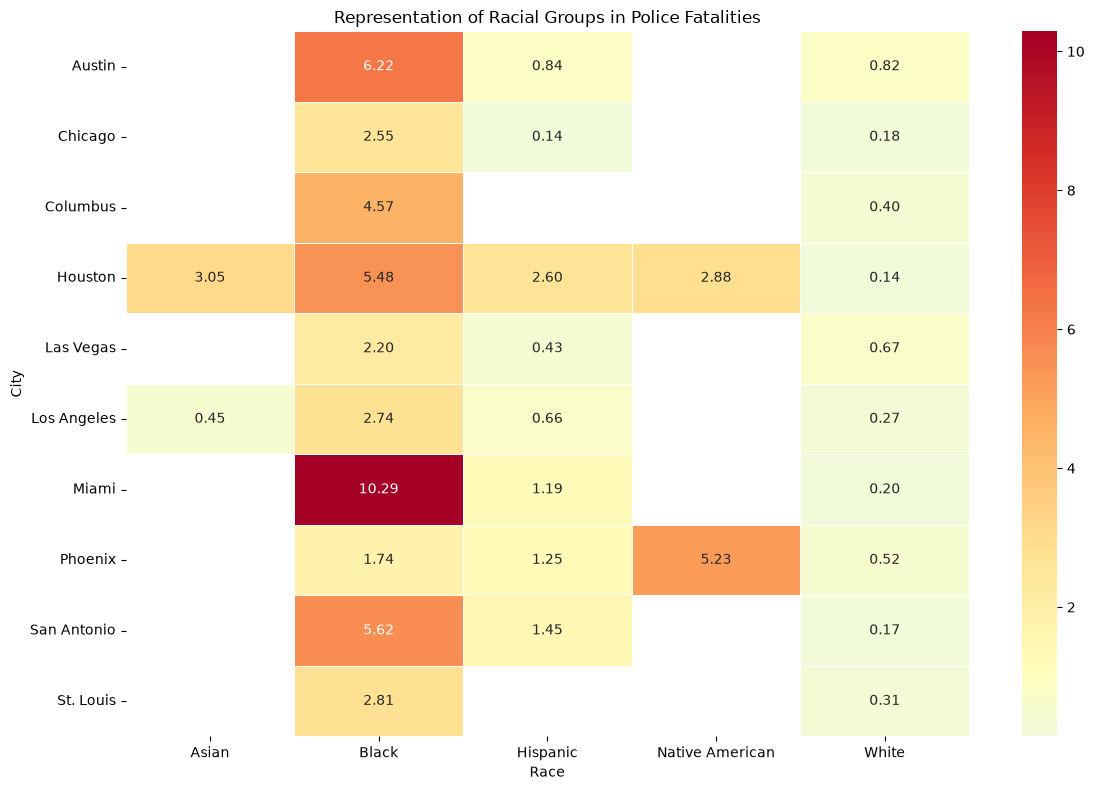

In [76]:
heatmap_data = comparison.pivot(
    index="city_key",
    columns="race",
    values="representation_ratio"
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="RdYlBu_r",
    center=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Representation of Racial Groups in Police Fatalities")
plt.xlabel("Race")
plt.ylabel("City")
plt.tight_layout()
plt.show()

# Create a Choropleth Map of Police Killings by US State

Which states are the most dangerous? Compare your map with your previous chart. Are these the same states with high degrees of poverty? 

In [77]:
import plotly.express as px

state_counts = (
    df_fatalities["state"]
    .value_counts()
    .rename_axis("state")
    .reset_index(name="fatalities")
)

print("Top 10 states:")
print(state_counts.head(10))

Top 10 states:
  state  fatalities
0    CA         424
1    TX         225
2    FL         154
3    AZ         118
4    OH          79
5    OK          78
6    CO          74
7    GA          70
8    NC          69
9    MO          64


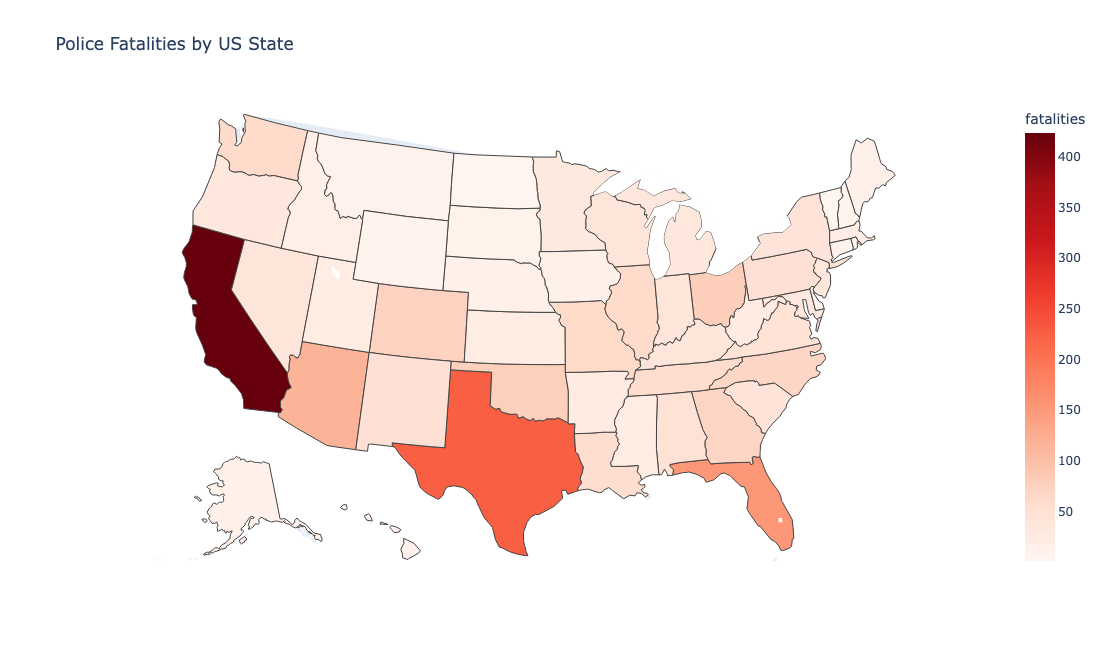

In [78]:
fig = px.choropleth(
    state_counts,
    locations="state",
    locationmode="USA-states",
    color="fatalities",
    scope="usa",
    color_continuous_scale="Reds",
    title="Police Fatalities by US State"
)

fig.update_layout(
    width=1000,
    height=650
)

fig.show()

In [82]:
# Rebuild state-wise fatality counts
state_counts = (
    df_fatalities["state"]
    .value_counts()
    .rename_axis("state")
    .reset_index(name="fatalities")
)

# Convert state abbreviations to full names
state_counts["Geographic Area"] = state_counts["state"].map(state_names)

# Rebuild poverty data using the abbreviation-to-name mapping
poverty_data = poverty_by_state.copy()

poverty_data["Geographic Area"] = (
    poverty_data["Geographic Area"].map(state_names)
)

# Remove unmatched states
state_counts = state_counts.dropna(subset=["Geographic Area"])
poverty_data = poverty_data.dropna(subset=["Geographic Area"])

# Merge the datasets
comparison_states = pd.merge(
    state_counts[["Geographic Area", "fatalities"]],
    poverty_data[["Geographic Area", "poverty_rate"]],
    on="Geographic Area",
    how="inner"
)

print("Matched states:", len(comparison_states))

# Top 10 states by fatalities
top_fatality_states = comparison_states.nlargest(10, "fatalities")

# Top 10 states by poverty
top_poverty_states = comparison_states.nlargest(10, "poverty_rate")

print("\nTop 10 states by police fatalities:")
print(top_fatality_states[["Geographic Area", "fatalities"]].to_string(index=False))

print("\nTop 10 states by poverty rate:")
print(top_poverty_states[["Geographic Area", "poverty_rate"]].to_string(index=False))

# Common states
common_states = set(top_fatality_states["Geographic Area"]) & set(
    top_poverty_states["Geographic Area"]
)

print("\nStates appearing in both lists:")
print(sorted(common_states))

Matched states: 50

Top 10 states by police fatalities:
Geographic Area  fatalities
     California         424
          Texas         225
        Florida         154
        Arizona         118
           Ohio          79
       Oklahoma          78
       Colorado          74
        Georgia          70
 North Carolina          69
       Missouri          64

Top 10 states by poverty rate:
Geographic Area  poverty_rate
    Mississippi         26.88
        Arizona         25.67
        Georgia         23.78
     New Mexico         23.08
       Arkansas         22.96
      Louisiana         22.34
 South Carolina         22.16
  West Virginia         21.13
       Oklahoma         20.66
        Alabama         20.65

States appearing in both lists:
['Arizona', 'Georgia', 'Oklahoma']


# Number of Police Killings Over Time

Analyse the Number of Police Killings over Time. Is there a trend in the data? 

In [84]:
df_fatalities["date"] = pd.to_datetime(
    df_fatalities["date"],
    format="mixed",
    errors="coerce"
)

df_fatalities["year"] = df_fatalities["date"].dt.year

In [85]:
yearly_killings = df_fatalities["year"].value_counts().sort_index()

print(yearly_killings)

year
2015    991
2016    963
2017    581
Name: count, dtype: int64


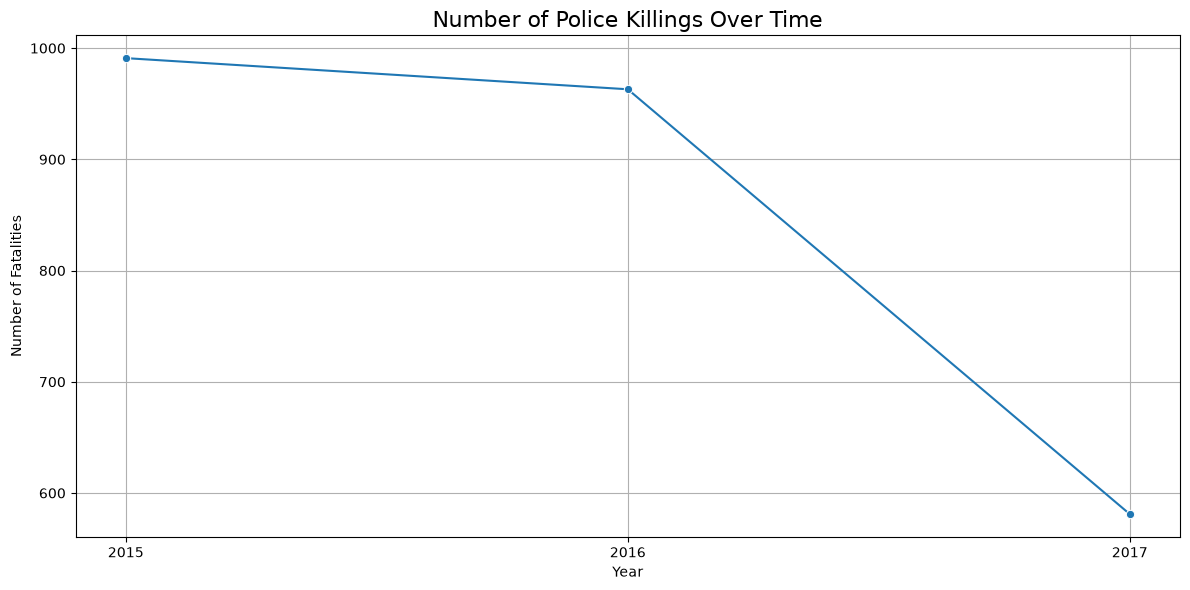

In [86]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=yearly_killings.index,
    y=yearly_killings.values,
    marker="o"
)

plt.title("Number of Police Killings Over Time", fontsize=16)
plt.xlabel("Year")
plt.ylabel("Number of Fatalities")
plt.xticks(yearly_killings.index)
plt.grid(True)
plt.tight_layout()
plt.show()

In [87]:
print("Year with most killings:", yearly_killings.idxmax())
print("Number of killings:", yearly_killings.max())

Year with most killings: 2015
Number of killings: 991


# Epilogue

Now that you have analysed the data yourself, read [The Washington Post's analysis here](https://www.washingtonpost.com/graphics/investigations/police-shootings-database/).

## Epilogue

After analysing the dataset and reading The Washington Post's investigation, I found that fatal police shootings are a serious issue in the United States.

My analysis showed that:
- California had the highest number of recorded fatalities in the dataset.
- Most victims were male.
- A significant proportion of victims were reported as unarmed or showing signs of mental illness.
- Black and Hispanic victims appeared disproportionately represented in several city-level comparisons.

The analysis also helped me understand that raw fatality counts do not tell the complete story. Population size, demographics, and other factors must also be considered.

Overall, this project helped me develop practical skills in Python, Pandas, Matplotlib, Seaborn, and Plotly, while showing me how data analysis can be used to understand important social issues.